In [24]:
import geopandas as gpd
import matplotlib.pyplot as plt
import os
import numpy as np
from osgeo import gdal
from sklearn.metrics import confusion_matrix
import pandas as pd


## Testing each group for metrics and total metrics

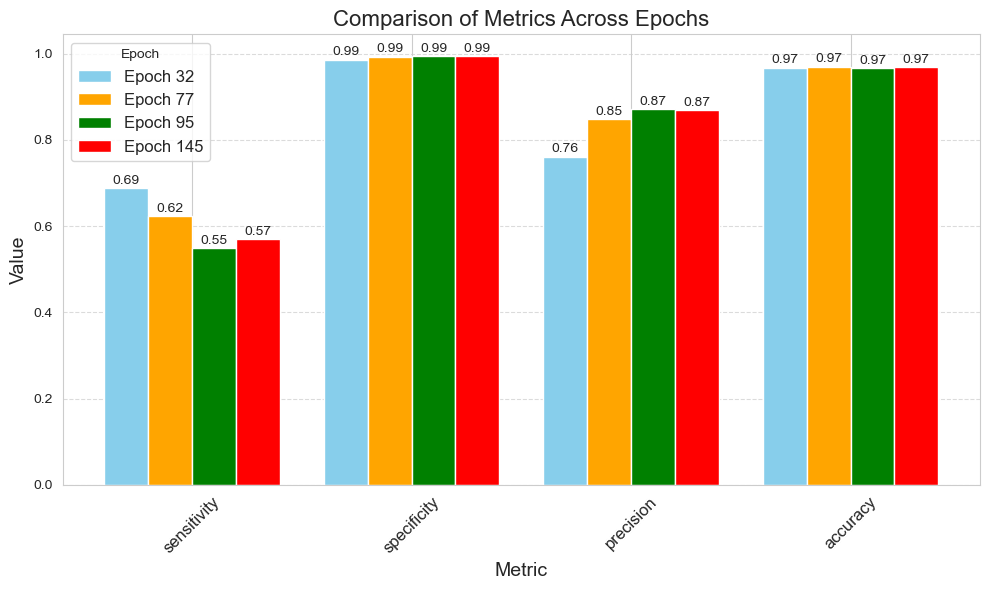

In [53]:


# Step 1: Load the CSV file into a DataFrame
data = pd.read_csv("/Users/nirgut/Documents/Master_Files/UNet_files/Full_Combined_Predictions/total_metrics_perpix.csv")
df = pd.DataFrame(data)

# Step 2: Define metrics and epochs
metrics = ["sensitivity", "specificity", "precision", "accuracy"]
epochs = df["Epoch"]
values = [df[metric] for metric in metrics]

# Step 3: Initialize the plot
x = np.arange(len(metrics))  # Positions for metrics
width = 0.2  # Width of bars
colors = ['skyblue', 'orange', 'green', 'red']

plt.figure(figsize=(10, 6))

# Step 4: Plot bars for each epoch
for i, epoch in enumerate(epochs):
    bar_values = [df.iloc[i][metric] for metric in metrics]
    bars = plt.bar(x + i * width, bar_values, width=width, label=f"Epoch {epoch}", color=colors[i])
    
    # Annotate each bar with its value
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width() / 2,  # Center text horizontally
            height + 0.01,  # Slightly above the bar
            f"{height:.2f}",  # Format value to two decimal places
            ha='center',
            fontsize=10
        )

# Step 5: Customize the plot
plt.title("Comparison of Metrics Across Epochs", fontsize=16)
plt.xlabel("Metric", fontsize=14)
plt.ylabel("Value", fontsize=14)
plt.xticks(x + width * 1.5, metrics, rotation=45, fontsize=12)  # Adjust x-ticks to center
plt.legend(title="Epoch", fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Show the plot
plt.tight_layout()
plt.show()


In [42]:
def calculate_metrics(pred_dir, mask_dir, metrics_path):
    # Initialize counters for global metrics
    global_tp, global_fp, global_fn, global_tn = 0, 0, 0, 0
    metrics_list = []

    # Get list of prediction files
    pred_files = [f for f in os.listdir(pred_dir) if f.endswith('.tif')]

    for file in pred_files:

        pred_path = os.path.join(pred_dir, file)
        mask_path = os.path.join(mask_dir, file)

        # Load prediction and mask rasters
        pred_ds = gdal.Open(pred_path)
        mask_ds = gdal.Open(mask_path)
        
        if pred_ds is None or mask_ds is None:
            print(f"Could not open files for {file}")
            continue

        pred_array = pred_ds.GetRasterBand(1).ReadAsArray()
        mask_array = mask_ds.GetRasterBand(1).ReadAsArray()

        # Ensure the arrays are binary (0, 1) for metrics calculation
        pred_binary = (pred_array > 0).astype(int)
        mask_binary = (mask_array > 0).astype(int)

        # Flatten arrays for comparison
        pred_flat = pred_binary.flatten()
        mask_flat = mask_binary.flatten()

        # Calculate confusion matrix
        tn, fp, fn, tp = confusion_matrix(mask_flat, pred_flat, labels=[0, 1]).ravel()

        # Update global metrics
        global_tp += tp
        global_fp += fp
        global_fn += fn
        global_tn += tn

        # Calculate individual metrics
        sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
        specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0
        accuracy = (tp + tn) / (tp + tn + fp + fn) if (tp + tn + fp + fn) > 0 else 0
        

        # extract the number in the file name 'group17.tif'
        group_number = file.split('.')[0]
        group_number = group_number.split('group')[1]
        
        # Append individual metrics to list
        metrics_list.append({
            'Group': group_number,
            'sensitivity': sensitivity,
            'specificity': specificity,
            'precision': precision,
            'accuracy': accuracy
        })

        print(f"Metrics for group {group_number}:")
        print(f"  Sensitivity: {sensitivity:.4f}")
        print(f"  Specificity: {specificity:.4f}")
        print(f"  Precision: {precision:.4f}")
        print(f"  Accuracy: {accuracy:.4f}")

    # Calculate overall metrics
    total_sensitivity = global_tp / (global_tp + global_fn) if (global_tp + global_fn) > 0 else 0
    total_specificity = global_tn / (global_tn + global_fp) if (global_tn + global_fp) > 0 else 0
    total_precision = global_tp / (global_tp + global_fp) if (global_tp + global_fp) > 0 else 0
    total_accuracy = (global_tp + global_tn) / (global_tp + global_tn + global_fp + global_fn) if (global_tp + global_tn + global_fp + global_fn) > 0 else 0

    print("\nOverall Metrics:")
    print(f"  Sensitivity: {total_sensitivity:.4f}")
    print(f"  Specificity: {total_specificity:.4f}")
    print(f"  Precision: {total_precision:.4f}")
    print(f"  Accuracy: {total_accuracy:.4f}")
    
        # save metrics to a csv file
    metrics_df = pd.DataFrame(metrics_list)
    
    # if path does not exist, create it
    if not os.path.exists(os.path.dirname(metrics_path)):
        os.makedirs(os.path.dirname(metrics_path))
    
    metrics_df.to_csv(metrics_path, index=False)
    
    # save total metrics to a csv file
    total_metrics_df = pd.DataFrame({
        'total_sensitivity': [total_sensitivity],
        'total_specificity': [total_specificity],
        'total_precision': [total_precision],
        'total_accuracy': [total_accuracy]
    })
    
    total_metrics_df.to_csv(metrics_path.replace('metrics.csv', 'total_metrics.csv'), index=False)

    return metrics_list, {
        'total_sensitivity': total_sensitivity,
        'total_specificity': total_specificity,
        'total_precision': total_precision,
        'total_accuracy': total_accuracy
    }







In [47]:
# Usage
pred_dir = "/Users/nirgut/Documents/Master_Files/UNet_files/Full_Combined_Predictions/epoch145/threshold0.5/binary_rasters"
mask_dir = "/Users/nirgut/Documents/Master_Files/UNet_files/Base_Rasters/Mask_test_groups"
metrics_path = '/Users/nirgut/Documents/Master_Files/UNet_files/Full_Combined_Predictions/epoch145/threshold0.5/metrics/metrics.csv'
calculate_metrics(pred_dir, mask_dir, metrics_path)



Metrics for group 18:
  Sensitivity: 0.8093
  Specificity: 0.9914
  Precision: 0.7000
  Accuracy: 0.9869
Metrics for group 19:
  Sensitivity: 0.0181
  Specificity: 0.9998
  Precision: 0.5692
  Accuracy: 0.9836
Metrics for group 8:
  Sensitivity: 0.3000
  Specificity: 0.9937
  Precision: 0.2841
  Accuracy: 0.9879
Metrics for group 9:
  Sensitivity: 0.8680
  Specificity: 0.9801
  Precision: 0.6358
  Accuracy: 0.9757
Metrics for group 7:
  Sensitivity: 0.6396
  Specificity: 0.9985
  Precision: 0.7488
  Accuracy: 0.9961
Metrics for group 6:
  Sensitivity: 0.6622
  Specificity: 0.9919
  Precision: 0.7538
  Accuracy: 0.9799
Metrics for group 4:
  Sensitivity: 0.4577
  Specificity: 0.9964
  Precision: 0.9731
  Accuracy: 0.8760
Metrics for group 5:
  Sensitivity: 0.7643
  Specificity: 0.9874
  Precision: 0.8665
  Accuracy: 0.9659
Metrics for group 1:
  Sensitivity: 0.8990
  Specificity: 0.9995
  Precision: 0.7955
  Accuracy: 0.9993
Metrics for group 2:
  Sensitivity: 0.7336
  Specificity: 0.99

([{'Group': '18',
   'sensitivity': 0.8092974356630251,
   'specificity': 0.9913692801648691,
   'precision': 0.699982208867891,
   'accuracy': 0.9869490189985796},
  {'Group': '19',
   'sensitivity': 0.018106250771573185,
   'specificity': 0.9997703858414255,
   'precision': 0.5692108667529108,
   'accuracy': 0.9835923936631944},
  {'Group': '8',
   'sensitivity': 0.3,
   'specificity': 0.9936730674544559,
   'precision': 0.2841225626740947,
   'accuracy': 0.9879150390625},
  {'Group': '9',
   'sensitivity': 0.8679867261499242,
   'specificity': 0.980054578559179,
   'precision': 0.6358323808297246,
   'accuracy': 0.9757317437065972},
  {'Group': '7',
   'sensitivity': 0.6396140749148694,
   'specificity': 0.9985482867479318,
   'precision': 0.7488372093023256,
   'accuracy': 0.9961357116699219},
  {'Group': '6',
   'sensitivity': 0.662211118051218,
   'specificity': 0.9918800632332453,
   'precision': 0.753839590443686,
   'accuracy': 0.9799488208912037},
  {'Group': '4',
   'sensiti

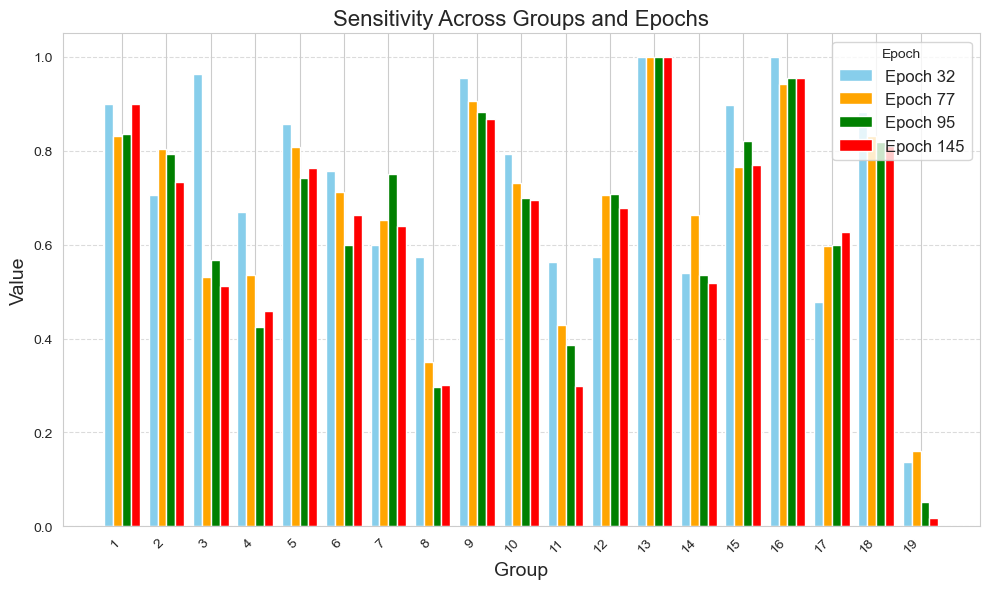

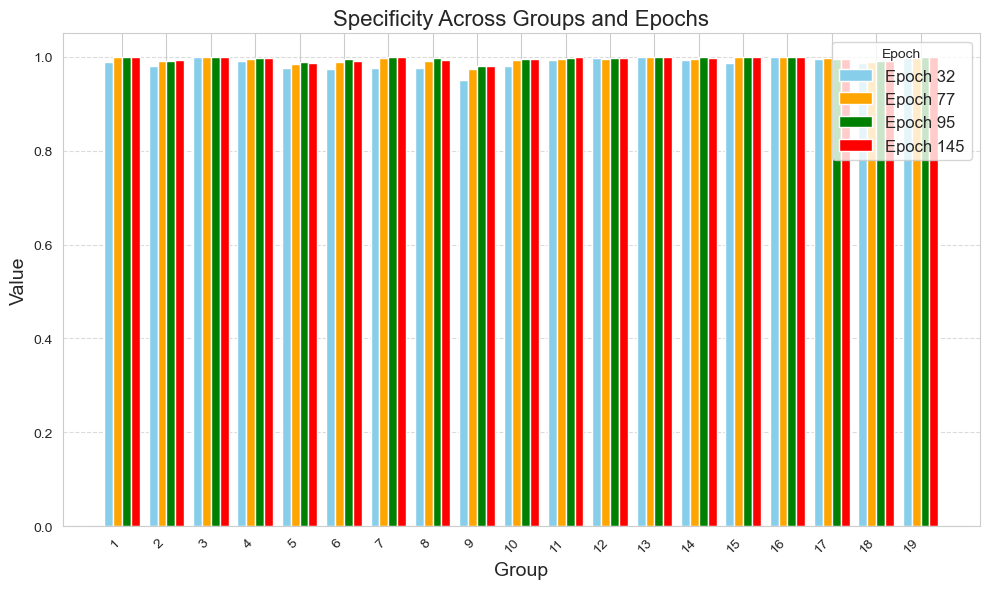

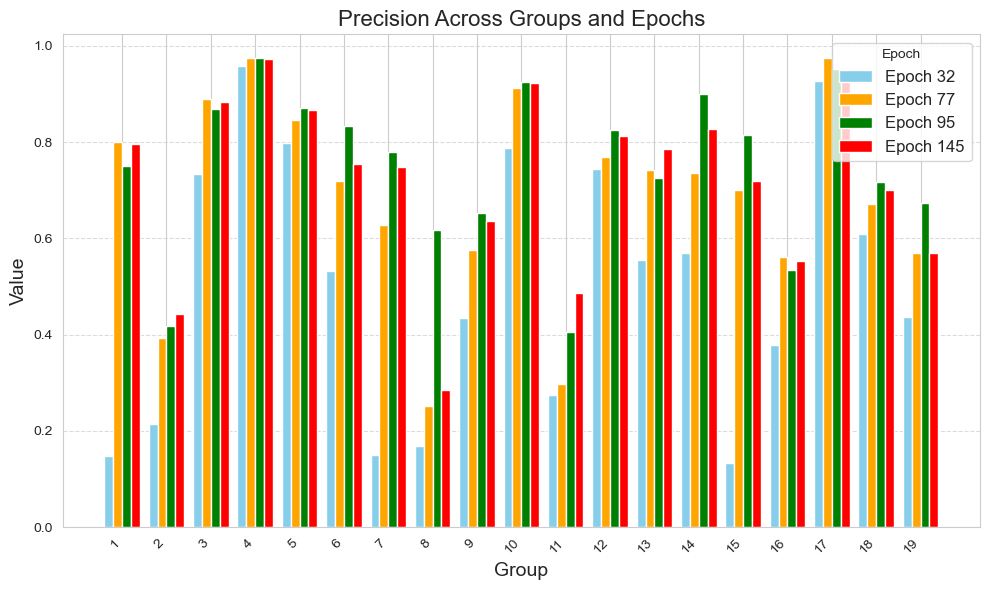

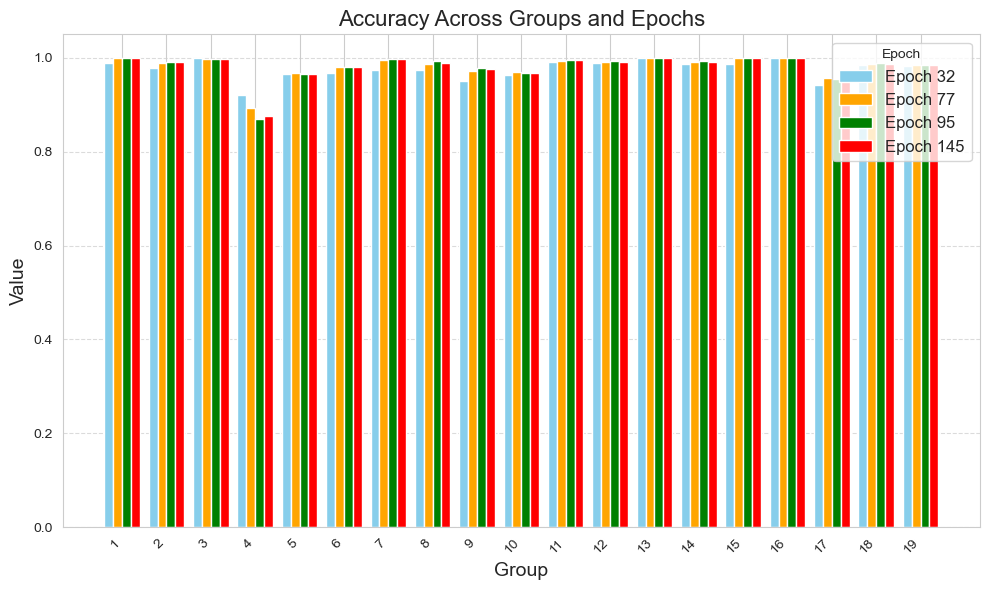

In [36]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Step 1: Load CSV files for each epoch into DataFrames
file_paths = {
    "Epoch 32": "/Users/nirgut/Documents/Master_Files/UNet_files/Full_Combined_Predictions/epoch32/threshold0.5/metrics/metrics.csv",
    "Epoch 77": "/Users/nirgut/Documents/Master_Files/UNet_files/Full_Combined_Predictions/epoch77/threshold0.5/metrics/metrics.csv",
    "Epoch 95": "/Users/nirgut/Documents/Master_Files/UNet_files/Full_Combined_Predictions/epoch95/threshold0.5/metrics/metrics.csv",
    "Epoch 145": "/Users/nirgut/Documents/Master_Files/UNet_files/Full_Combined_Predictions/epoch145/threshold0.5/metrics/metrics.csv",
}

dataframes = {epoch: pd.read_csv(path) for epoch, path in file_paths.items()}

# Step 2: Extract the metrics and groups
metrics = ['sensitivity', 'specificity', 'precision', 'accuracy']
groups = dataframes["Epoch 32"]['Group']  # Assuming all epochs have the same groups

# Step 3: Plot each metric separately
colors = ['skyblue', 'orange', 'green', 'red']  # Colors for each epoch

for metric in metrics:
    plt.figure(figsize=(10, 6))
    
    # Step 3a: Plot bars for each epoch
    x = np.arange(len(groups))  # X positions for groups
    width = 0.2  # Bar width
    for j, (epoch, df) in enumerate(dataframes.items()):
        values = df[metric]
        plt.bar(x + j * width, values, width=width, label=epoch, color=colors[j])
    
    # Step 3b: Customize the plot
    plt.title(f"{metric.capitalize()} Across Groups and Epochs", fontsize=16)
    plt.xticks(x + (width * 1.5), groups, rotation=45, ha='right')
    plt.xlabel("Group", fontsize=14)
    plt.ylabel("Value", fontsize=14)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.legend(fontsize=12, title="Epoch")
    
    # Show the plot
    plt.tight_layout()
    plt.show()



# Per polygon analysis

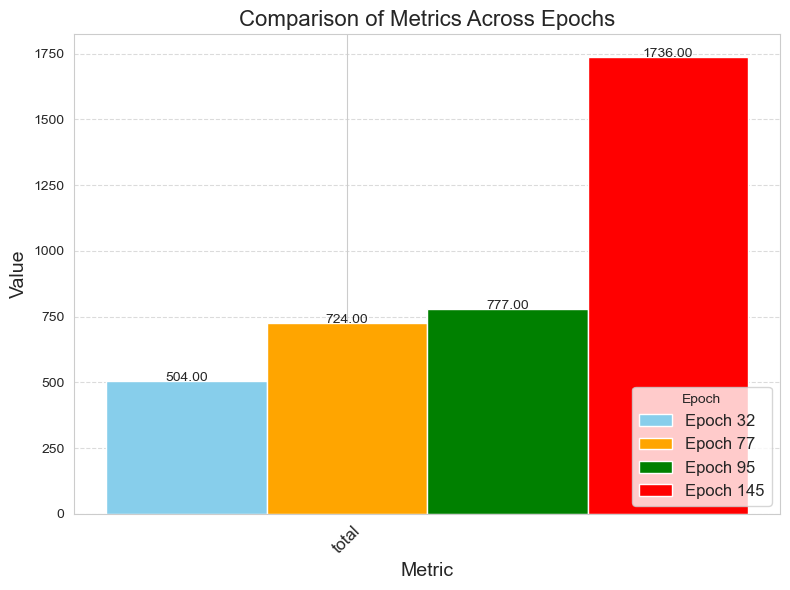

In [60]:
# Step 1: Load the CSV file into a DataFrame
data = pd.read_csv("/Users/nirgut/Documents/Master_Files/UNet_files/Full_Combined_Predictions/total_metrics_perpoly.csv")
df = pd.DataFrame(data)

# Step 2: Define metrics and epochs
metrics = [ "sensitivity", "precision"]
# metrics = [ "total"]
epochs = df["Epoch"]
values = [df[metric] for metric in metrics]

# Step 3: Initialize the plot
x = np.arange(len(metrics))  # Positions for metrics
width = 0.1  # Width of bars
colors = ['skyblue', 'orange', 'green', 'red']

plt.figure(figsize=(8, 6))

# Step 4: Plot bars for each epoch
for i, epoch in enumerate(epochs):
    bar_values = [df.iloc[i][metric] for metric in metrics]
    bars = plt.bar(x + i * width, bar_values, width=width, label=f"Epoch {epoch}", color=colors[i])
    
    # Annotate each bar with its value
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width() / 2,  # Center text horizontally
            height + 0.01,  # Slightly above the bar
            f"{height:.2f}",  # Format value to two decimal places
            ha='center',
            fontsize=10
        )

# Step 5: Customize the plot
plt.title("Comparison of Metrics Across Epochs", fontsize=16)
plt.xlabel("Metric", fontsize=14)
plt.ylabel("Value", fontsize=14)
plt.xticks(x + width , metrics, rotation=45, fontsize=12)  # Adjust x-ticks to center
plt.legend(title="Epoch", fontsize=12, loc='lower right')
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Show the plot
plt.tight_layout()
plt.show()


# Plotting size histogram of predicted sinkholes

Number of sinkholes: 1736
Mean Area: 218.4894377880184
Median Area: 14.25
Standard Deviation: 1516.8894303020443
Number of sinkholes smaller than 5 m²: 490


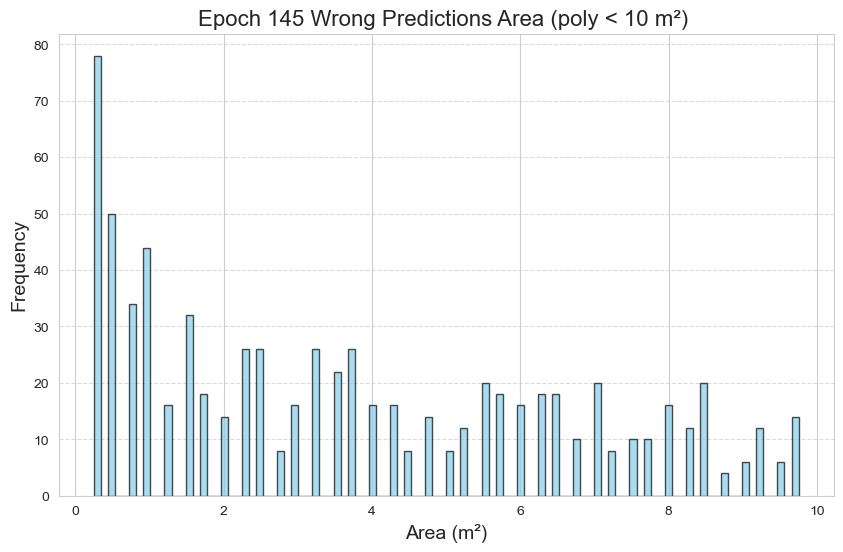

In [69]:
# Step 1: Load the shapefile
shapefile_path = "/Users/nirgut/Documents/Master_Files/UNet_files/Full_Combined_Predictions/epoch145/threshold0.5/epoch145_0.5thresh_combined.shp"
# shapefile_path = "/Users/nirgut/Documents/Master_Files/UNet_files/Full_Combined_Predictions/epoch145/threshold0.5/wrong_sink_preds.shp"
gdf = gpd.read_file(shapefile_path)

# Step 2: Access the 'Area' field
# Ensure 'Area' field exists
if 'Area' not in gdf.columns:
    raise ValueError("'Area' field not found in the shapefile")

areas = gdf['Area']


print(f"Number of sinkholes: {len(areas)}")
print(f"Mean Area: {areas.mean()}")
print(f"Median Area: {areas.median()}")
print(f"Standard Deviation: {areas.std()}")

# how many are bigger than 1000
print(f"Number of sinkholes smaller than 5 m²: {len(areas[areas < 5])}")

# filter areas bigger than 0
areas = areas[areas < 10]

# Step 3: Plot the histogram
plt.figure(figsize=(10, 6))
plt.hist(areas, bins=100, color='skyblue', edgecolor='black', alpha=0.7)
# plt.title("Histogram of Sinkhole Area Sizes", fontsize=16)
plt.title("Epoch 145 Wrong Predictions Area (poly < 10 m²) ", fontsize=16)
plt.xlabel("Area (m²)", fontsize=14)
plt.ylabel("Frequency", fontsize=14)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Show the plot
plt.show()


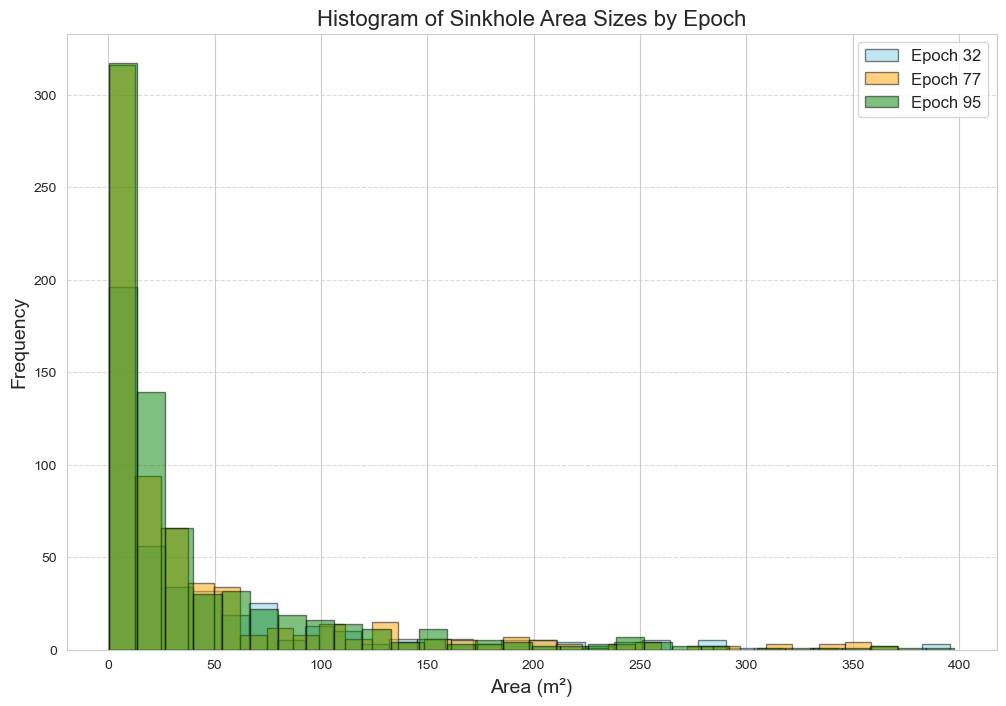

In [18]:
››import geopandas as gpd
import matplotlib.pyplot as plt

# Step 1: Define shapefile paths and corresponding epochs
shapefile_paths = {
    "Epoch 32": "/Users/nirgut/Documents/Master_Files/UNet_files/Full_Combined_Predictions/epoch32/threshold0.5/epoch32_0.5thresh_combined.shp",
    "Epoch 77": "/Users/nirgut/Documents/Master_Files/UNet_files/Full_Combined_Predictions/epoch77/threshold0.5/epoch77_0.5thresh_combined.shp",
    "Epoch 95": "/Users/nirgut/Documents/Master_Files/UNet_files/Full_Combined_Predictions/epoch95/threshold0.5/epoch95_0.5thresh_combined.shp",
    # "Epoch 145": "/Users/nirgut/Documents/Master_Files/UNet_files/Full_Combined_Predictions/epoch145/threshold0.5/epoch145_0.5thresh_combined.shp",
}

# Step 2: Initialize the plot
plt.figure(figsize=(12, 8))
colors = ['skyblue', 'orange', 'green', 'red']  # Colors for each histogram

# Step 3: Loop through shapefiles, extract 'Area', and plot histograms
for epoch, path in zip(shapefile_paths.keys(), shapefile_paths.values()):
    # Load shapefile
    gdf = gpd.read_file(path)
    
    # Check if 'Area' field exists
    if 'Area' not in gdf.columns:
        raise ValueError(f"'Area' field not found in {epoch}")

    # Extract 'Area' values
    areas = gdf['Area']
    
    # filter areas bigger than 0
    areas = areas[areas < 400]

    # Plot histogram
    plt.hist(areas, bins=30, alpha=0.5, label=epoch, edgecolor='black', color=colors.pop(0))

# Step 4: Customize the plot
plt.title("Histogram of Sinkhole Area Sizes by Epoch", fontsize=16)
plt.xlabel("Area (m²)", fontsize=14)
plt.ylabel("Frequency", fontsize=14)
plt.legend(fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Show the plot
plt.show()
